In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gspread 
from google.oauth2.service_account import Credentials
import matplotlib.dates as mdates

In [2]:
# Google auth
scope = [
    "https://www.googleapis.com/auth/spreadsheets",
    "https://www.googleapis.com/auth/drive"
]

creds = Credentials.from_service_account_file(
    "/workspaces/steel_stock_management/credentials.json",
    scopes=scope
)

gc = gspread.authorize(creds)

sheet = gc.open_by_url("https://docs.google.com/spreadsheets/d/1qAsFjW2lT8e54FsvsMkfGIHwQEDxsQuf4SzVAMXlK-g/edit?gid=824196706#gid=824196706")


In [3]:
inventory_ws = sheet.worksheet('inventario')
mat_dict_ws = sheet.worksheet('mat_dict') 

In [ ]:
inventory_df = pd.DataFrame(inventory_ws.get_all_records())
materials_df = pd.DataFrame(mat_dict_ws.get_all_records())

In [5]:
# Raw data and preprocessing
df_raw = inventory_df.copy()

df_baking = df_raw.copy()

# Convert dates from columns back into rows
df_baking = df_baking.melt(
    id_vars="material",
    var_name="fecha",
    value_name="inventario"
)

# Preprocessing
df_baking['fecha'] = pd.to_datetime(df_baking['fecha'])
df_baking["material"] = df_baking["material"].astype("category")

df_baking = df_baking.set_index('fecha')

df = df_baking.copy()

df.head()

,material,inventario
fecha,,
2026-05-19,ALAMBRE RECOCIDO,1924.63
2026-05-19,ALAMBRON,1108.00
2026-05-19,ARMEX DE 15 x 15,551.00
2026-05-19,ARMEX DE 15 x 20,9.00
2026-05-19,"CLAVO P/CONCRETO 2 1/2"" GALV 1 KG",295.00


In [19]:
df.to_csv('/workspaces/steel_stock_management/data/inventory_df.csv', index=True)
materials_df.to_csv('/workspaces/steel_stock_management/data/mat_dict.csv', index=False)

In [ ]:
# Material dict
mat_dict = materials_df.set_index("material").to_dict(orient="index")

In [11]:
def choose_annotation_position(ax, x_point, y_point):
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()

    x_num = mdates.date2num(pd.to_datetime(x_point))

    x_mid = (x_min + x_max) / 2
    y_mid = (y_min + y_max) / 2

    # If point is high, put label below
    # If point is low, put label above
    if y_point > y_mid:
        y_offset = -35
        va = "top"
    else:
        y_offset = 35
        va = "bottom"

    # If point is near right, put label left
    # If point is near left, put label right
    if x_num > x_mid:
        x_offset = -35
        ha = "right"
    else:
        x_offset = 35
        ha = "left"

    return (x_offset, y_offset), ha, va

In [14]:
def display_graphics(ax, material, purchase_date, received, quantity, unit, minimum_stock):

    mat = df[df["material"] == material].copy()

    mat = mat.reset_index()

    sns.lineplot(
        data=mat,
        x='fecha',
        y="inventario",
        linewidth=2.5,
        ax=ax
    )

    ax.set_title(material.upper())
    ax.set_xlabel("Día")
    ax.set_ylabel("Inventario")
    ax.tick_params(axis='x', rotation=45)

    ax.axhline(
        minimum_stock,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Mínimo"
    )

    ax.axvline(
        pd.to_datetime(received),
        color="green",
        linestyle="--",
        linewidth=2,
        label="Recibido"
    )

    ax.axvline(
        pd.to_datetime(purchase_date),
        color="black",
        linestyle="--",
        linewidth=2,
        label="Pedido"
    )

    purchase_dt = pd.to_datetime(purchase_date)
    received_dt = pd.to_datetime(received)

    mat = mat.reset_index()  # brings fecha back as a column
    mat["fecha"] = pd.to_datetime(mat["fecha"])

    closest_idx = (mat["fecha"] - purchase_dt).abs().idxmin()
    closest_inventory = mat.loc[closest_idx, "inventario"]

    y_min, y_max = ax.get_ylim()
    y_range = y_max - y_min

    # Keep the label inside the graph
    text_y = min(closest_inventory + 0.08 * y_range, y_max - 0.08 * y_range)

    offset, ha, va = choose_annotation_position(
        ax,
        received_dt,
        closest_inventory
    )

    ax.annotate(
        f"{quantity} {unit}",
        xy=(received_dt, closest_inventory),
        xytext=offset,
        textcoords="offset points",
        ha=ha,
        va=va,
        arrowprops=dict(
            arrowstyle="->",
            lw=1.5,
            shrinkA=2,
            shrinkB=2
        ),
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            alpha=0.85
        ),
        clip_on=True
    )

    mat = mat.copy()
    mat["daily_change"] = mat["inventario"].diff()
    consumption = -mat["daily_change"]
    consumption = consumption[consumption > 0]
    avg = consumption.mean()

    ax.text(
        0.02, 0.95,
        f"Consumo:\n{avg:.1f}/{unit}/Día",
        transform=ax.transAxes,
        fontsize=9,
        va="top",
        bbox=dict(boxstyle="round", facecolor="white")
    )

    ax.legend(fontsize=8)

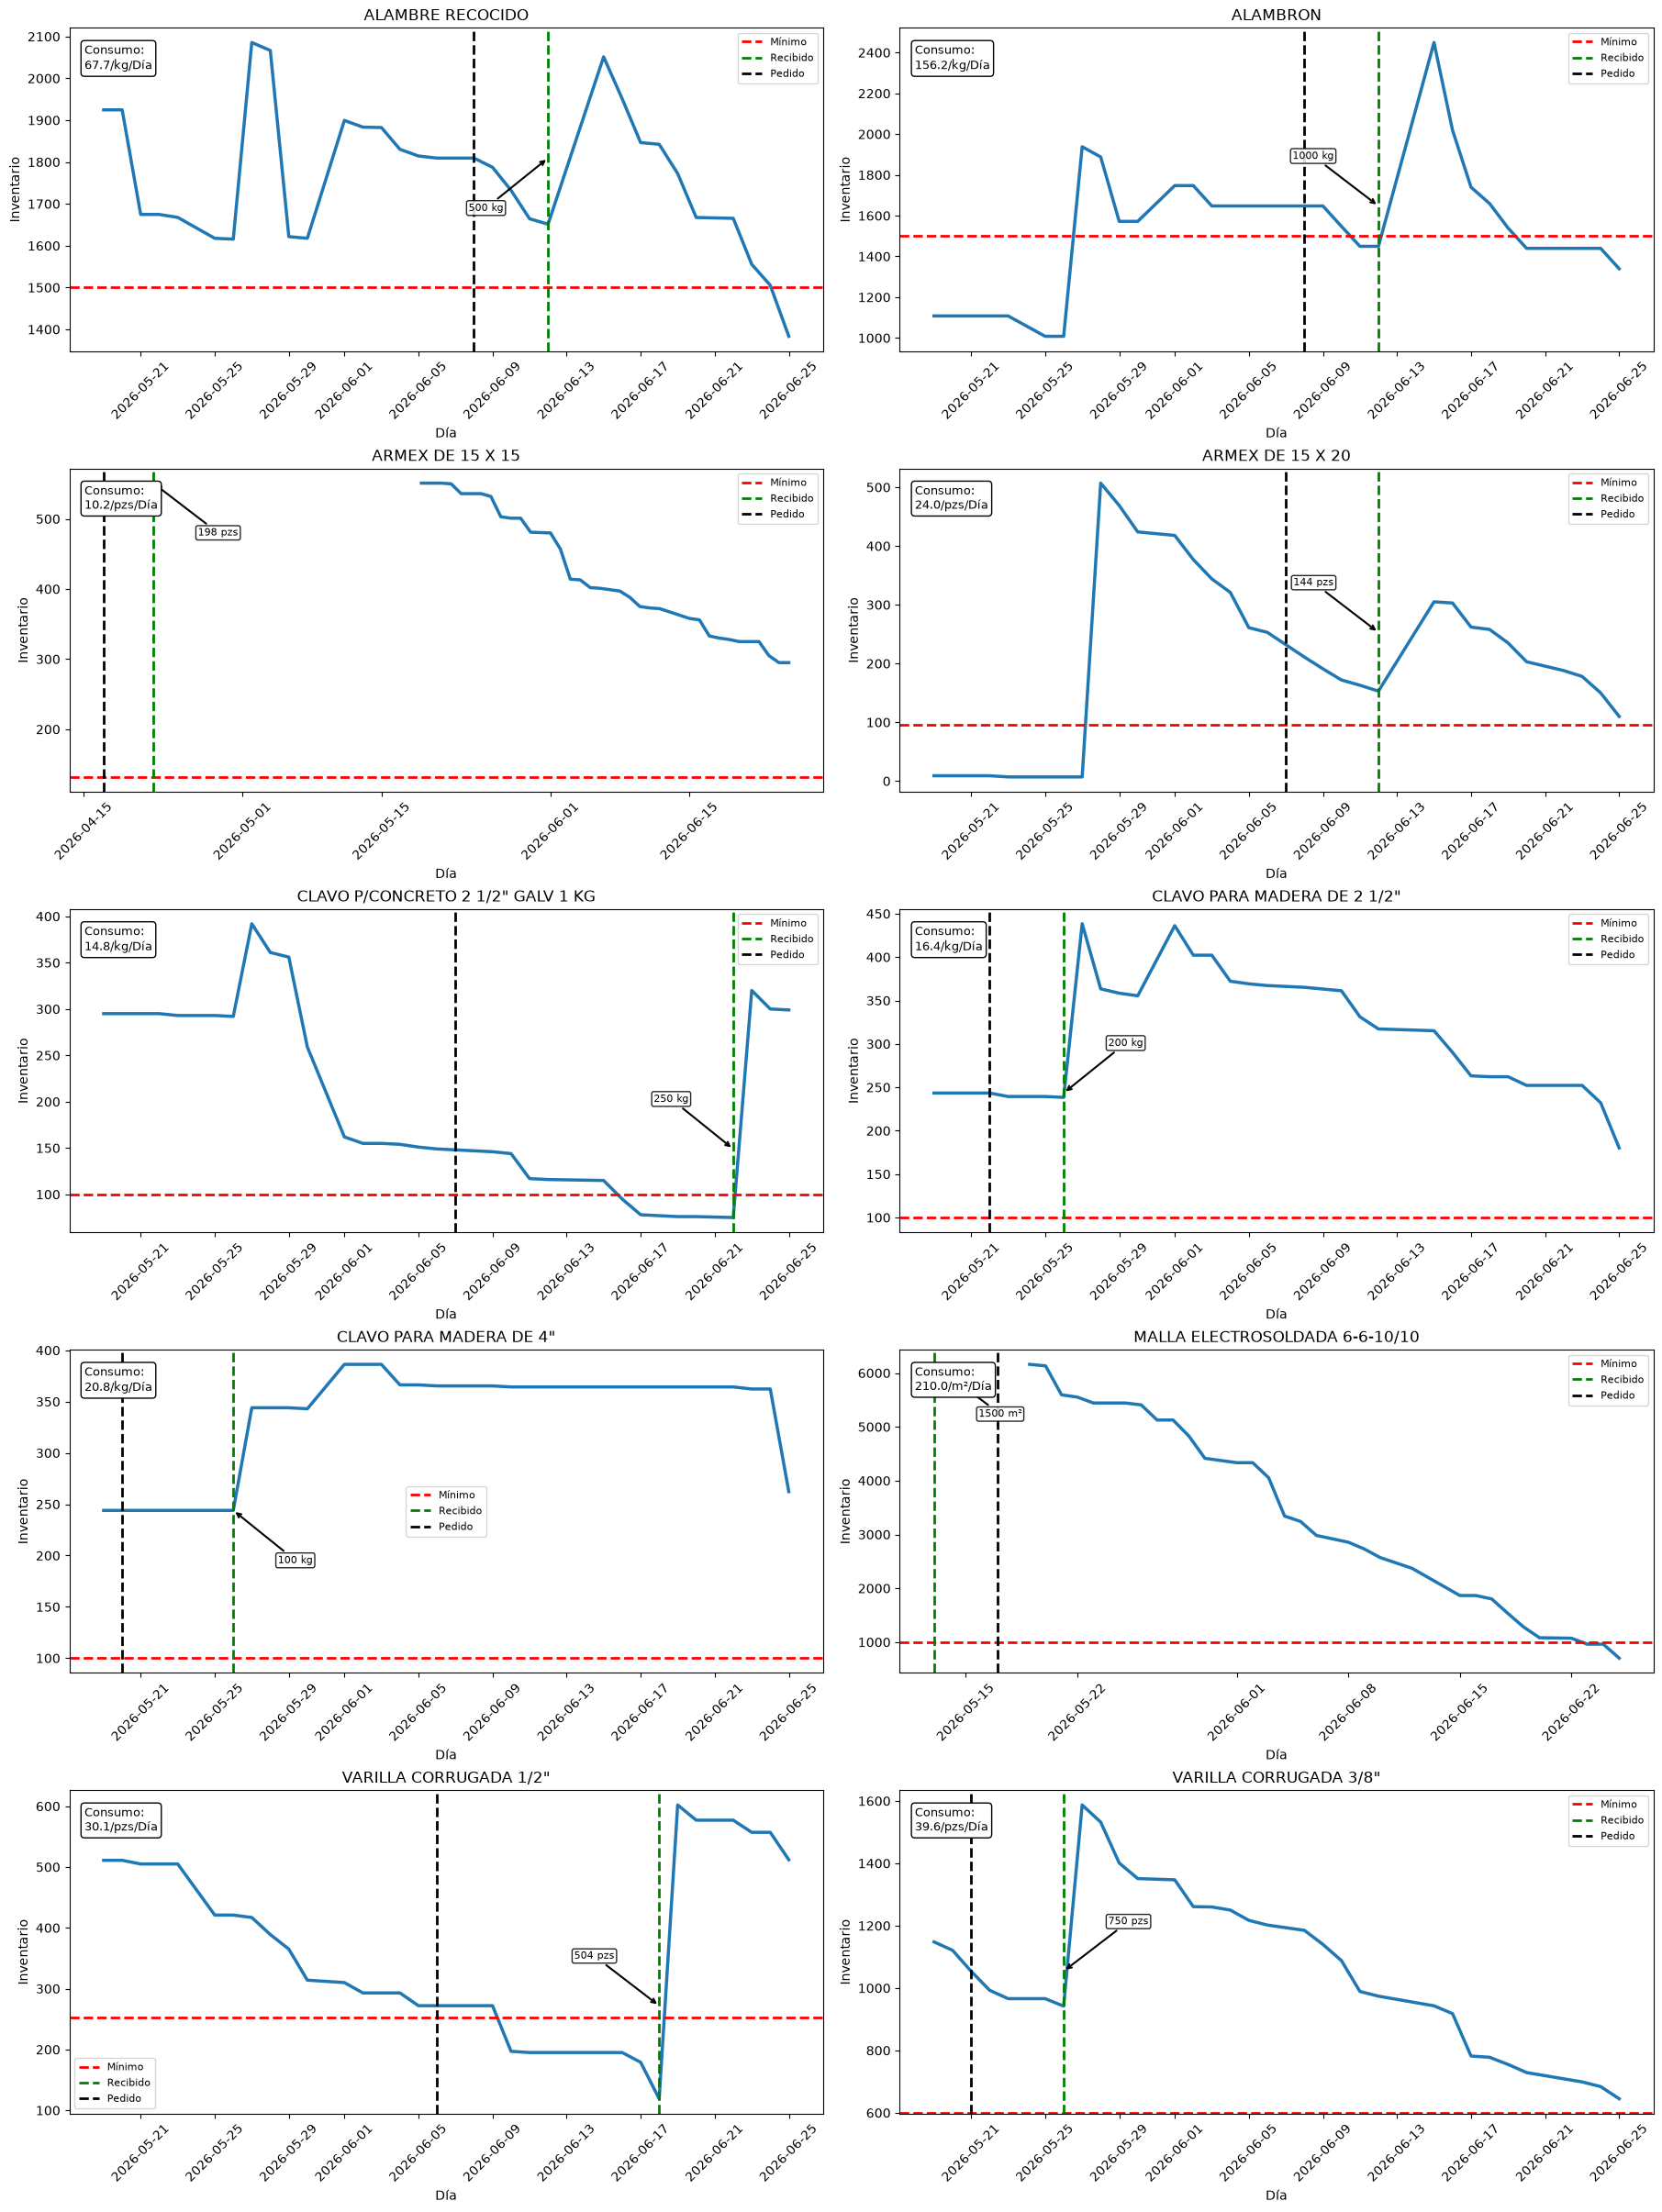

In [16]:
fig, axes = plt.subplots(5, 2, figsize=(18, 24), constrained_layout=True)

axes = axes.flatten()

for ax, (material, info) in zip(axes, mat_dict.items()):

    display_graphics(
        ax,
        material,
        info["purchase_date"],
        info["received"],
        info["quantity"],
        info["unit"],
        info["minimum_stock"]
    )

for ax in axes[len(mat_dict):]:
    ax.axis('offc')

fig.savefig(
    "inventario_aceros.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()